# H2 City Hotel – Exploratory Data Analysis


| Section | EDA |
|---|---|
| 0 | Data cleaning decisions |
| 1 | ADR distribution: raw and log |
| 2 | What drives ADR: month × year, room type, market segment |



## 0. Data cleaning decisions

In [551]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# display all columns and rows automatically assigned
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)


darkjungle= "#1e201f"
mediumjungle= "#193a31"
deepgreen= "#1d6c61"
verdigris= "#3e89ab"
forestgreen= "#5aa371"
mist= "#e6eeeb"          

# correlations: verdigris (negative) -> white -> deep green (positive)
from matplotlib.colors import LinearSegmentedColormap
corr_cmap = LinearSegmentedColormap.from_list("jungle", [verdigris, "#ffffff", deepgreen])

#"#e6e5e1"

#dpi for resolution
#bbox to remove extra whitespace
#axis below grid lines, title on left, bold title
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": mist, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.edgecolor": mediumjungle,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": darkjungle, "axes.labelcolor": darkjungle, "axes.titlecolor": mediumjungle,
    "xtick.color": mediumjungle, "ytick.color": mediumjungle,
    "axes.prop_cycle": plt.cycler(color=[deepgreen, verdigris, forestgreen, mediumjungle]),
})

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name))

def iqr_bounds(s):
    # [Q1 - 1.5 IQR, Q3 + 1.5 IQR]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def iqr_flags(s):
    # True where a value is outside the IQR bounds
    low, high = iqr_bounds(s)
    return (s < low) | (s > high)

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]


The EDAs in this section use a separate raw copy (exact duplicates dropped, spaces trimmed and `NULL`/`NA` turned into NaN, nothing else removed), because their job is to justify the cleaning.

In [552]:
raw = pd.read_csv("DatasetML.csv")
n_file = len(raw)
raw = raw.drop_duplicates()
raw = raw.apply(lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x))
raw = raw.replace(["NULL", "NA", ""], np.nan)
print("Rows in file:", n_file, "  after dropping duplicates:", raw.shape)

Rows in file: 79330   after dropping duplicates: (53428, 31)


#### Missing values

          missing      %
Company     50646  94.79
Agent        5587  10.46
Country         6   0.01
Children        4   0.01


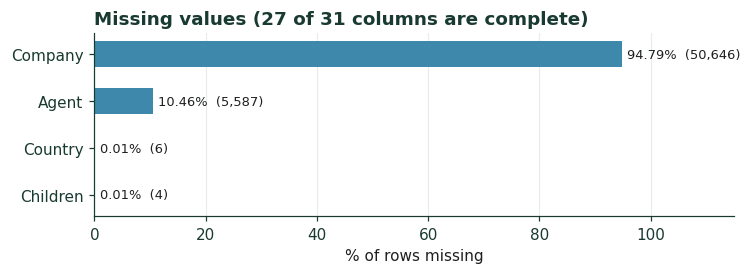

In [553]:
miss = raw.isna().sum()
miss = miss[miss > 0].sort_values()
pct = miss / len(raw) * 100
print(pd.DataFrame({"missing": miss, "%": pct.round(2)}).sort_values("missing", ascending=False))

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(miss.index, pct, color=verdigris, height=0.55)
for b, n, p in zip(bars, miss, pct):
    ax.text(p + 1, b.get_y() + b.get_height() / 2, f"{p:.2f}%  ({n:,})", va="center", fontsize=8.5)
ax.set_xlim(0, 115); ax.set_xlabel("% of rows missing"); ax.grid(axis="y", visible=False)
ax.set_title(f"Missing values ({len(raw.columns) - len(miss)} of {len(raw.columns)} columns are complete)")
plt.tight_layout(); save("00a_missing_values.png"); plt.show()

we had to see if the presence of a company in the data had any effect on the values of the other columns. We grouped the data by whether or not a company was present and calculated the mean for each numeric column. We then calculated the difference between the means for those with a company and those without. The results were printed in a summary table, showing the average values for each group and the difference between them.

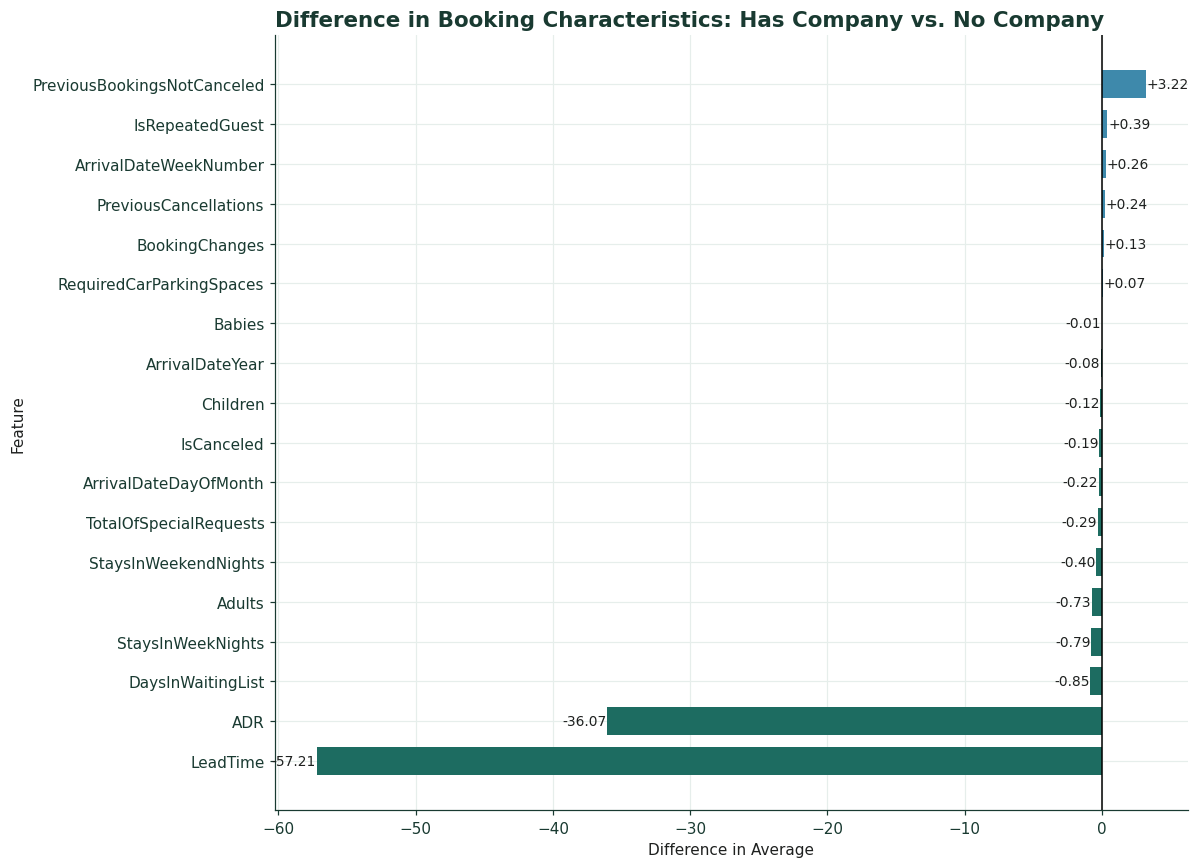

In [554]:

group = raw["Company"].notna().map({False: "No company", True: "Has company"})
cols = raw.select_dtypes(include="number").columns

summary = raw[cols].groupby(group).mean().T[["No company", "Has company"]]
summary["Difference"] = summary["Has company"] - summary["No company"]


# Sort differences for better readability
diff = summary["Difference"].sort_values()

fig, ax = plt.subplots(figsize=(11, 8))
colors = [deepgreen if x < 0 else verdigris for x in diff]

bars = ax.barh(diff.index, diff.values, color=colors, height=0.7)

# Reference line at zero
ax.axvline(0, color="black", linewidth=1)

# Add values next to bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (0.05 if width >= 0 else -0.05),
        bar.get_y() + bar.get_height() / 2,
        f"{width:+.2f}",
        va="center",
        ha="left" if width >= 0 else "right",
        fontsize=9
    )

ax.set_title(
    "Difference in Booking Characteristics: Has Company vs. No Company",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Difference in Average")
ax.set_ylabel("Feature")

plt.tight_layout(); save("00a2_company_difference.png"); plt.show()

The bar chart above shows that having a company makes a lot of difference in the LeadTime and ADR features therefore we cannot fully drop the column without loosing the data in it without storing it someway first.

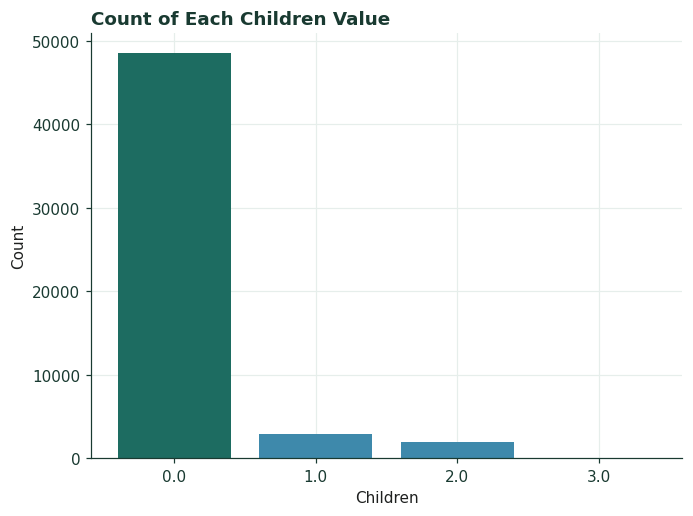

In [555]:
#count number of each value in children
children_count = raw["Children"].value_counts()
children_count_df = pd.DataFrame({"Children": children_count.index, "Count": children_count.values})

colors = [deepgreen if v == children_count.max() else verdigris for v in children_count.values]

plt.bar(children_count.index.astype(str), children_count.values, color=colors)
plt.xlabel("Children")
plt.ylabel("Count")
plt.title("Count of Each Children Value")

plt.tight_layout(); save("00a3_children_counts.png"); plt.show()

The bar chart above shows that zero is the most common children value and so that is the value we will use to replace the missing values.

**Decision:** Only 4 columns have missing values: Company 94.79%, Agent 10.46%, Country 6 rows and Children 4 rows.
- So for Company, it has been decided to make a HasCompany boolean column then dropping the column Company itself since the IDs for the companies are too little to use.
- As for Agent, we decided to add agent 0 meaning that there is no travel agent
- missing children to be assigned zero which is the most common value
- as for country we just dropped those rows that had missing countries which were only 3

#### Box plots of LeadTime and stay lengths

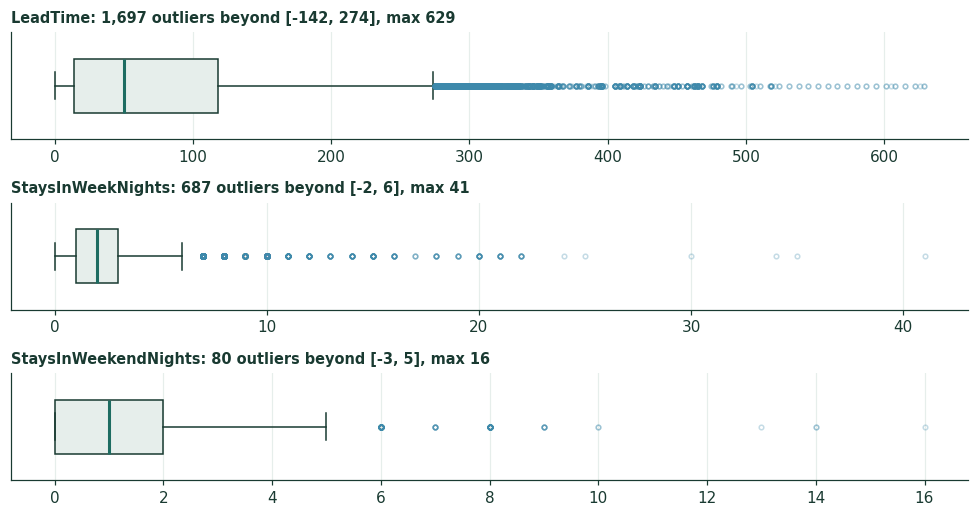

In [556]:
cols = ["LeadTime", "StaysInWeekNights", "StaysInWeekendNights"]

fig, axes = plt.subplots(len(cols), 1, figsize=(9, 1.6 * len(cols)))
for ax, col in zip(axes, cols):
    s = raw[col]
    low, high = iqr_bounds(s)
    n_out = iqr_flags(s).sum()
    ax.boxplot(s, widths=0.5, patch_artist=True, boxprops=dict(facecolor=mist, edgecolor=mediumjungle),
               whiskerprops=dict(color=mediumjungle), capprops=dict(color=mediumjungle),
               medianprops=dict(color=deepgreen, lw=2),
               flierprops=dict(marker="o", markersize=3, alpha=0.3, markeredgecolor=verdigris), orientation="horizontal")
    ax.set_yticks([])
    ax.set_title(f"{col}: {n_out:,} outliers beyond [{low:.0f}, {high:.0f}], max {s.max():,.0f}", fontsize=9.5)
plt.tight_layout(); save("00b_outlier_boxplots.png"); plt.show()

**Decision:** LeadTime has a long right tail (up to 629 days), week nights reach 41 and weekend nights 16
The usual IQR rule is applied to these three columns, after Adults = 0 is removed: **LeadTime > 274** (1,679 rows), **StaysInWeekNights > 6** (662) and **StaysInWeekendNights > 5** (73) are removed. The plot counts above are slightly higher because they still include the Adults = 0 rows.


#### ADR by reserved room type

ADR is not filtered with one global range. Prices depend strongly on the room and on the number of guests, so one range would cut most premium-room bookings and keep cheap-room errors. The cleaning computes a separate IQR range for each **room type × party size** group (see `load1.ipynb`). These boxes split ADR by room type only, so their whiskers are close to, but not exactly, the limits the cleaning uses.

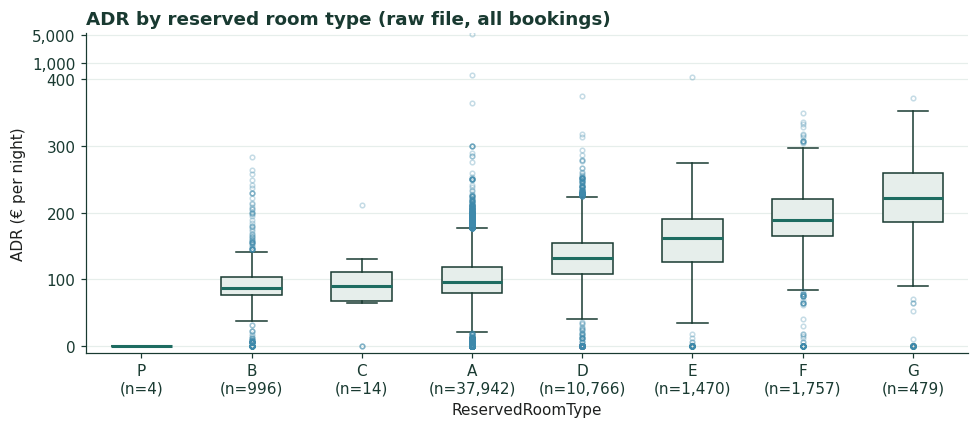

Top 5 ADR values:
5400.00
 510.00
 451.50
 375.50
 372.33


In [557]:
raw_room = raw["ReservedRoomType"]
order = raw.groupby(raw_room)["ADR"].median().sort_values().index
data = [raw.loc[raw_room == k, "ADR"] for k in order]

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(data, widths=0.55, patch_artist=True, boxprops=dict(facecolor=mist, edgecolor=mediumjungle),
           whiskerprops=dict(color=mediumjungle), capprops=dict(color=mediumjungle),
           medianprops=dict(color=deepgreen, lw=2),
           flierprops=dict(marker="o", markersize=3, alpha=0.3, markeredgecolor=verdigris))
ax.set_xticks(range(1, len(order) + 1), [f"{k}\n(n={len(d):,})" for k, d in zip(order, data)])
ax.set_yscale("symlog", linthresh=400, linscale=6)     # linear up to €400, compressed above, so the 5,400 point fits
ax.set_ylim(bottom=-10); ax.set_yticks([0, 100, 200, 300, 400, 1000, 5000], ["0", "100", "200", "300", "400", "1,000", "5,000"])
ax.set_xlabel("ReservedRoomType"); ax.set_ylabel("ADR (€ per night)"); ax.grid(axis="x", visible=False)
ax.set_title("ADR by reserved room type (raw file, all bookings)")
plt.tight_layout(); save("00b2_adr_by_roomtype.png"); plt.show()

print("Top 5 ADR values:"); print(raw["ADR"].sort_values(ascending=False).head(5).to_string(index=False))

**Decision:** ADR has one point at 5,400, more than 10× the next highest (510) so it is probably a human error. 

- ADR outliers are found within each room type × party size group (and groups with fewer than 100 bookings are merged with the next party size, and if the room as a whole is less than 100 entries then we use party size alone). This removes 1,782 rows

here ends the data cleaning decision EDAs, now will import the cleaned dataset. any mention of "raw" here and forward means the cleaned df

In [558]:

df = pd.read_csv("H2_cleaned.csv")
df["ReservationStatusDate"] = pd.to_datetime(df["ReservationStatusDate"])

# helper columns for the EDA (not saved anywhere)
df["ArrivalDateMonth"] = pd.Categorical(df["ArrivalDateMonth"], categories=MONTHS, ordered=True)
df["TotalNights"] = df["StaysInWeekendNights"] + df["StaysInWeekNights"]
df["TotalGuests"] = df["Adults"] + df["Children"] + df["Babies"]

print("Rows in file:", n_file, "  after cleaning:", len(df))
print("Cleaned shape:", df.shape, "  missing values:", int(df.isna().sum().sum()))

Rows in file: 79330   after cleaning: 48991
Cleaned shape: (48991, 33)   missing values: 0


## 1. ADR distribution: raw and log

**Purpose:** see the shape of the regression target after cleaning. A strongly skewed target hurts models that minimise squared error like mean sqaured error

count    48991.00
mean       112.93
std         38.09
min          0.00
25%         85.50
50%        106.25
75%        134.30
max        352.50
Name: ADR, dtype: float64

Skewness  raw: 1.06   log1p: -2.27


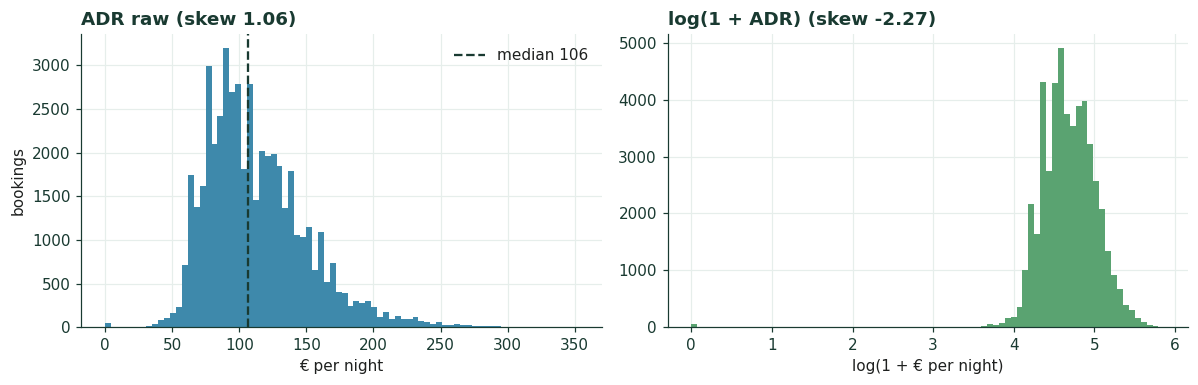

In [559]:
adr = df["ADR"]
print(adr.describe().round(2))
print(f"\nSkewness  raw: {adr.skew():.2f}   log1p: {np.log1p(adr).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(adr, bins=80, color=verdigris)
axes[0].axvline(adr.median(), color=mediumjungle, ls="--", lw=1.5, label=f"median {adr.median():.0f}")
axes[0].set_title(f"ADR raw (skew {adr.skew():.2f})"); axes[0].set_xlabel("€ per night")
axes[0].set_ylabel("bookings"); axes[0].legend(frameon=False)

axes[1].hist(np.log1p(adr), bins=80, color=forestgreen)
axes[1].set_title(f"log(1 + ADR) (skew {np.log1p(adr).skew():.2f})")
axes[1].set_xlabel("log(1 + € per night)")
plt.tight_layout(); save("01_adr_raw_vs_log.png"); plt.show()

ADR = 0 bookings removed: 49  (0.10%)
Skewness  raw: 1.09   log1p: 0.06


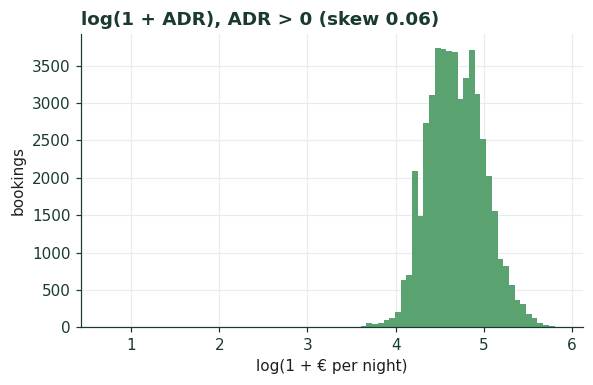

In [560]:

n_zero = (df["ADR"] == 0).sum()
adr_paid = df.loc[df["ADR"] > 0, "ADR"]
print(f"ADR = 0 bookings removed: {n_zero}  ({n_zero / len(df):.2%})")
print(f"Skewness  raw: {adr_paid.skew():.2f}   log1p: {np.log1p(adr_paid).skew():.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.hist(np.log1p(adr_paid), bins=80, color=forestgreen)
ax.set_title(f"log(1 + ADR), ADR > 0 (skew {np.log1p(adr_paid).skew():.2f})")
ax.set_xlabel("log(1 + € per night)"); ax.set_ylabel("bookings")
plt.tight_layout(); save("01b_adr_no_zero_log.png"); plt.show()

**Decision:** After cleaning, ADR ranges from 0 to 352.50 median being 106 and is moderately right-skewed (skew 1.06). The log transform over-corrects into a strong left skew (−2.27), but only because of the 49 bookings at €0
- The grouped rule keeps free stays but a free stay is not a price, so it makes more sense to remove ADR = 0 from the regression data
- Without those rows, log(1 + ADR) has almost no skew (0.06) against 1.09 for raw ADR. 

## 2. What drives ADR (regression)

**Purpose:** find which booking-time features explain the price, and whether time needs special treatment in the train/test split.

### 2.1 Median ADR by arrival month, one line per year

ArrivalDateYear    2015   2016   2017
ArrivalDateMonth                     
January             NaN   78.5   88.0
February            NaN   80.3   90.1
March               NaN   86.4   91.8
April               NaN   99.4  122.0
May                 NaN  116.1  134.0
June                NaN  110.0  130.0
July               76.5  114.3  125.1
August             85.3  121.5  139.0
September         103.1  125.1    NaN
October            96.0  113.0    NaN
November           73.0   89.0    NaN
December           79.0   90.7    NaN


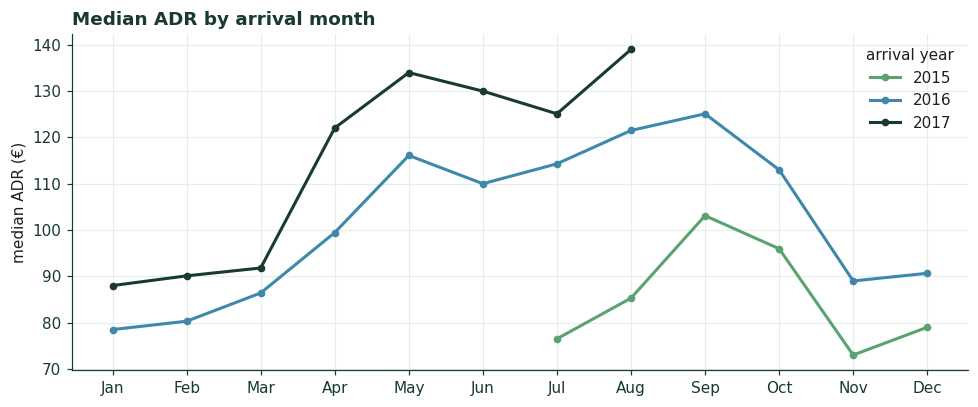

In [561]:
pivot = df.pivot_table(index="ArrivalDateMonth", columns="ArrivalDateYear",
                       values="ADR", aggfunc="median", observed=False)
print(pivot.round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
for year, color in zip(pivot.columns, [forestgreen, verdigris, mediumjungle]):
    ax.plot(range(1, 13), pivot[year].values, marker="o", ms=4, lw=2, color=color, label=str(year))
ax.set_xticks(range(1, 13), [m[:3] for m in MONTHS])
ax.set_ylabel("median ADR (€)"); ax.legend(title="arrival year", frameon=False)
ax.set_title("Median ADR by arrival month")
plt.tight_layout(); save("06_adr_month_year.png"); plt.show()

**Decision:** Prices follow the season (peak May–September) **and rise every year**: in every month present in both years, 2017 is above 2016 (for example April 99 to 122, August 122 to 139).
- **Keep ArrivalDateMonth** (encoded) and **ArrivalDateYear** as ADR predictors.
- Because prices trend upwards, a random split lets the model see future price levels. 

### 2.2 ADR by ReservedRoomType and by MarketSegment

Boxes are sorted by median. Every booking is shown; points beyond the whiskers are drawn as dots.

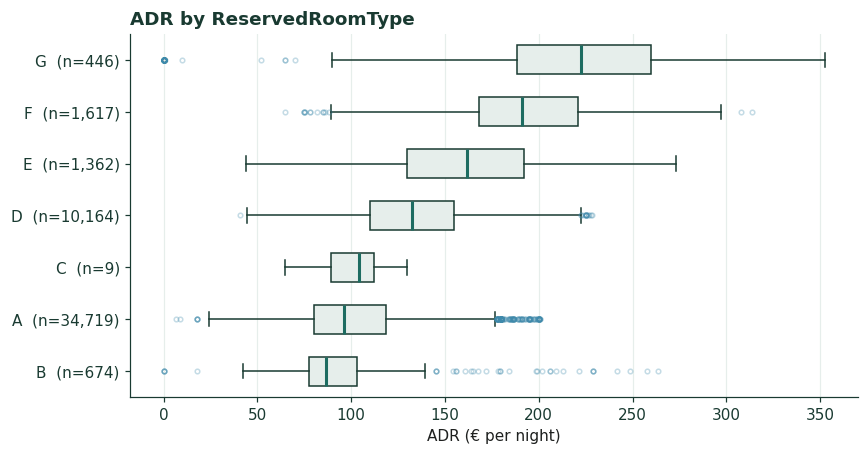

,n,median,mean
ReservedRoomType,,,
B,674,86.8,93.9
A,34719,96.3,100.5
C,9,104.0,101.2
D,10164,132.6,133.1
E,1362,162.0,162.8
F,1617,190.8,194.0
G,446,222.3,204.7


In [562]:
def adr_box(col, fname):
    order = df.groupby(col, observed=True)["ADR"].median().sort_values().index
    data = [df.loc[df[col] == k, "ADR"] for k in order]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) + 1.3))
    horiz = ({"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10)
             else {"vert": False})
    ax.boxplot(data, widths=0.55, patch_artist=True, boxprops=dict(facecolor=mist, edgecolor=mediumjungle),
               whiskerprops=dict(color=mediumjungle), capprops=dict(color=mediumjungle),
               medianprops=dict(color=deepgreen, lw=2),
               flierprops=dict(marker="o", markersize=3, alpha=0.3, markeredgecolor=verdigris), **horiz)
    labels = [f"{k}  (n={len(d):,})" for k, d in zip(order, data)]
    ax.set_yticks(range(1, len(order) + 1), labels)
    ax.set_xlabel("ADR (€ per night)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"ADR by {col}")
    plt.tight_layout(); save(fname); plt.show()
    return (df.groupby(col, observed=True)["ADR"]
              .agg(n="size", median="median", mean="mean").sort_values("median").round(1))

adr_box("ReservedRoomType", "07_adr_roomtype.png")

**Decision:** ADR rises with room type, from a median of about 96 for A to 222 for G
- to keep ReservedRoomType since it is the strongest ADR predictor (because AssignedRoomType would be considered data leakage). 

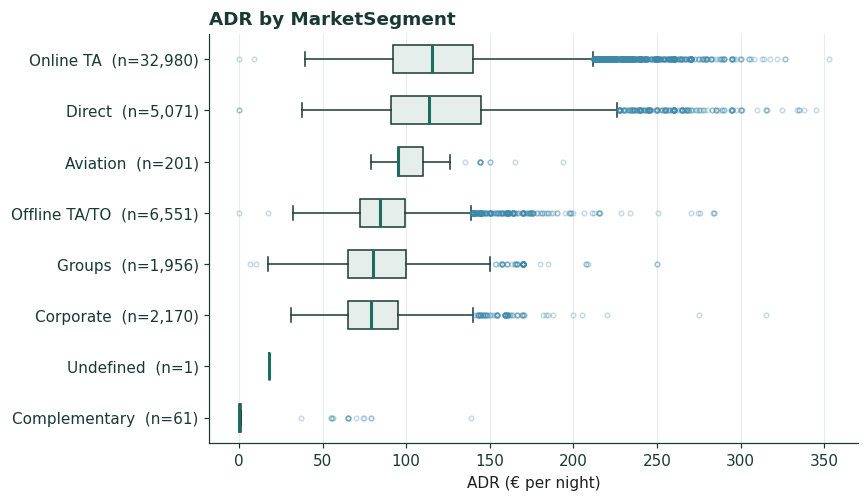

,n,median,mean
MarketSegment,,,
Complementary,61,0.0,17.0
Undefined,1,18.0,18.0
Corporate,2170,79.0,83.5
Groups,1956,80.0,87.2
Offline TA/TO,6551,84.6,87.8
Aviation,201,95.0,102.3
Direct,5071,113.4,122.7
Online TA,32980,115.2,120.1


In [563]:
adr_box("MarketSegment", "08_adr_segment.png")

**Decision:** Online TA and Direct pay the most with median about 113 115 and Corporate, Groups and Offline TA/TO the least with about 79–85
- keep MarketSegment for ADR